In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os
from scipy.signal import welch
from specula.mmlib.utils import get_pupil_mask

2026-11-05 08:46:42,850 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-05 08:46:43,012 [INFO]: [specula]: Default device is GPU number 0


In [2]:
import matplotlib as mpl
# from cycler import cycler

cmap = mpl.colormaps['hot'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 7)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
# plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'magma' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

In [3]:
calib_dir = '/raid1/mmenessini/calibration/WFSW'
result_dir = '/raid1/mmenessini/results/WFSW'

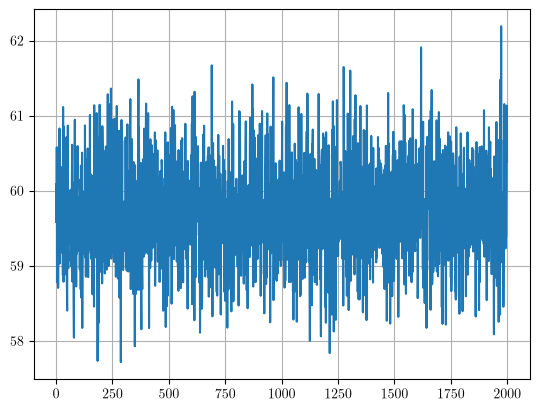

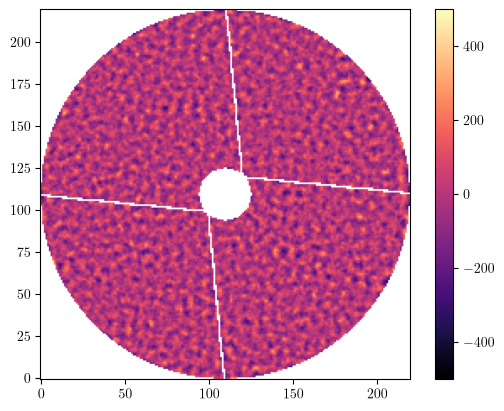

In [128]:
phi = fits.getdata(os.path.join(result_dir,'res_ef.fits'))[:,1,:,:]
amp = np.sum(fits.getdata(os.path.join(result_dir,'res_ef.fits'))[:,0,:,:],axis=0) > 0

phi -= np.mean(phi[:,amp],axis=1)[:,None,None]

plt.figure()
plt.plot(np.std(phi[:,amp],axis=1))
plt.grid()

plt.figure()
plt.imshow(np.ma.masked_array(phi[10]-phi[11],mask=(1-amp).astype(bool)),vmin=-500,vmax=500)
plt.colorbar()

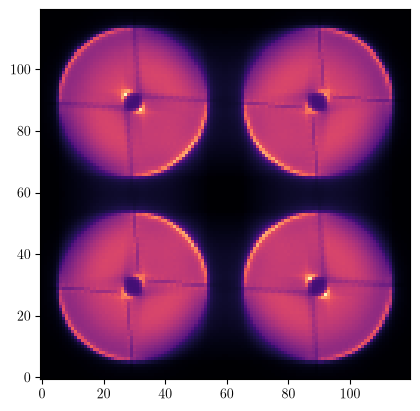

In [121]:
frames_vis = fits.getdata(os.path.join(result_dir,'vis_frames.fits'))
frames_nir = fits.getdata(os.path.join(result_dir,'nir_frames.fits'))

plt.figure()
plt.imshow(np.mean(frames_vis,axis=0))

In [4]:
X = np.array([1, 1, -1, -1])    # x^k for pupils A, B, C, D
Y = np.array([-1, 1, 1, -1])    # y^k for pupils A, B, C, D

def rec_noise_var(rec, mean_frame, pup, sigma_e, excess=1.0):
    """Per-mode photon and read-noise variance, in rec units squared."""
    f = mean_frame.ravel()
    I = np.array([f[pup[:, k][pup[:, k] >= 0]] for k in range(4)])
    sum_I = I.sum(axis=0).mean()
    N = I.shape[1]
    Rx, Ry = rec[:, :N], rec[:, N:]
    phot = np.zeros(rec.shape[0])
    read = np.zeros(rec.shape[0])
    for k in range(4):
        w2 = (X[k] * Rx + Y[k] * Ry)**2
        phot += excess**2 * (w2 @ np.maximum(I[k], 0.0))
        read += w2.sum(axis=1) * sigma_e**2
    return phot / sum_I**2, read / sum_I**2

def noise_sensitivities(rec, mean_frame, pup, wvl=None):
    """s_phot, s_read, Npix. flux defaults to the sum over the whole frame."""
    flux = np.sum(mean_frame)
    phot, read = rec_noise_var(rec, mean_frame, pup, sigma_e=1.0)
    if wvl is None:
        wvl = 1.0
    s_phot = np.sqrt(phot * flux) / wvl
    s_read = np.sqrt(read) * flux / wvl
    return s_phot, s_read

def propagated_noise_var(s_phot, s_read, flux, sigma_e, wvl=1.0, excess=1.0):
    phot = (excess * s_phot * wvl)**2 / flux
    read = (s_read * sigma_e * wvl)**2 / flux**2
    return phot, read

In [5]:
def get_noise_propagation(rMod, nSubaps, nModes, wvl, sigma_e, flux):
    frame = np.mean(fits.getdata(os.path.join(calib_dir,'aliasing',f'pyr{rMod:1.1f}_{nSubaps}x{nSubaps}_{nModes}modes_wvl900_frame.fits')),axis=0)
    pup = fits.getdata(os.path.join(calib_dir, 'pupils', f'pyr_pupdata_{nSubaps}x{nSubaps}.fits'), 1)
    rec = fits.getdata(os.path.join(calib_dir, 'rec', f'pyr{rMod:1.1f}_{nSubaps}x{nSubaps}_wvl900_bmc2k_vlt_{nModes}modes_rec.fits'), 1)
    s_phot, s_read = noise_sensitivities(rec, frame, pup, wvl=900)
    phot, read = propagated_noise_var(s_phot, s_read, flux=flux, sigma_e=sigma_e, wvl=wvl)
    return np.sqrt(phot+read)

def get_aliasing_power(rMod, nSubaps, nModes):
    alias = fits.getdata(os.path.join(calib_dir,'aliasing',f'pyr{rMod:1.1f}_{nSubaps}x{nSubaps}_{nModes}modes_wvl900_alias.fits'))
    return np.var(alias,axis=0)

def get_atmo_coeffs(dt, nLayers=10, windRMS=12.9):
    data = fits.getdata(os.path.join(calib_dir,'atmo',f'turb_coeffs_{1/dt:1.0f}Hz_{nLayers}layers_{windRMS}wind.fits'))
    return data[0],data[1],data[2]

In [6]:
from save_kalman_data import save_kalman_data
dt = 0.0005              # [s] loop time step (main.time_step)
n_subaps, n_modes = 48, 1300
flux_vis = 1.0e5         # photo-electrons per 2 ms VIS frame   <- per frame of each sensor
flux_nir = 2.5e4         # photo-electrons per 0.5 ms NIR frame
sigma_e = 0.5            # [e-] RON

a1, a2, q = get_atmo_coeffs(dt)
sensors = [
    dict(noise_var=get_noise_propagation(2.0, n_subaps, n_modes, 900, sigma_e, flux_vis) ** 2,
            aliasing=get_aliasing_power(2.0, n_subaps, n_modes),
            frame_steps=4, biased=False),
    dict(noise_var=get_noise_propagation(0.0, n_subaps, n_modes, 1300, sigma_e, flux_nir) ** 2,
            aliasing=get_aliasing_power(0.0, n_subaps, n_modes),
            frame_steps=1, biased=True),
]
root_dir = '/raid1/mmenessini/calibration/WFSW'   # main.root_dir (the one aoeb sets, if it overrides it)
fn = save_kalman_data('kf_ar2_1300modes_vis_nir', root_dir,
                        a1, a2, q, sensors, delay=1.5, n_modes=1300)
print('saved', fn)

saved /raid1/mmenessini/calibration/WFSW/filter/kf_ar2_1300modes_vis_nir.fits


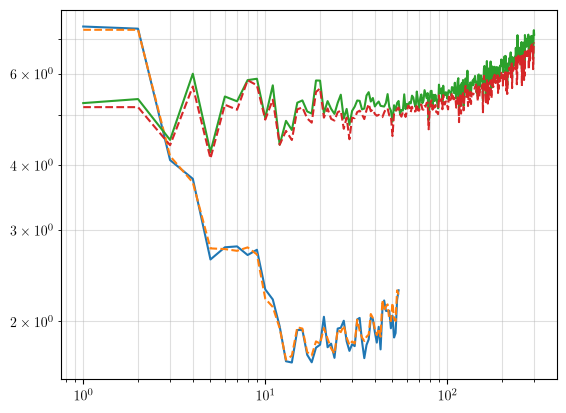

In [7]:
tn = '20261104_105059' # mag = 7
tn = '20261104_105155' # mag = 6
tn = '20261104_105300','20261104_110824','20261104_111252' # mag = 10
tn = '20261104_111754' # mag = 10, thr = -5
tn = '20261104_112815' # mag = 10, no clipping
tn = '20261104_121113' # mag = 11, no clipping
tn = '20261104_130003' # mag = 11, no clipping
noisev = fits.getdata(os.path.join(result_dir,tn,'meas_vis.fits'))
noiser = fits.getdata(os.path.join(result_dir,tn,'meas_nir.fits'))
frames_vis = fits.getdata(os.path.join(result_dir,tn,'vis_frames.fits'))
frames_nir = fits.getdata(os.path.join(result_dir,tn,'nir_frames.fits'))

noise_vis = get_noise_propagation(rMod=2, nSubaps=10, nModes=54, wvl=900, sigma_e=0.5, flux=np.sum(np.mean(frames_vis,axis=0)))
noise_nir = get_noise_propagation(rMod=0, nSubaps=24, nModes=300, wvl=1300, sigma_e=0.5, flux=np.sum(np.mean(frames_nir,axis=0)))

xv = np.arange(len(noisev.T))+1
xr = np.arange(len(noiser.T))+1

plt.loglog(xv, np.std(noisev, axis=0))
plt.loglog(xv, noise_vis[:len(xv)],'--')
plt.loglog(xr, np.std(noiser, axis=0))
plt.loglog(xr, noise_nir[:len(xr)],'--')
plt.grid(which='both',alpha=0.4)

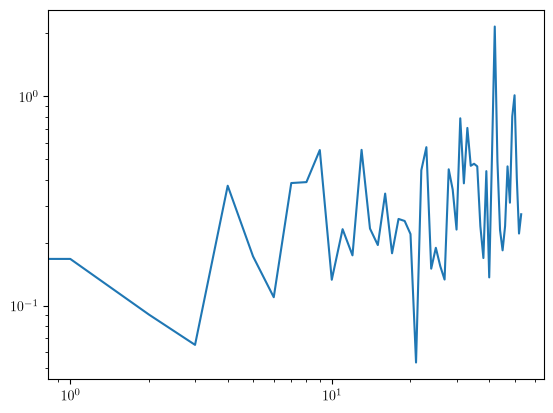

In [8]:
nModes = 54
nSubaps = 10
rMod = 0
alias = fits.getdata(os.path.join(calib_dir,'aliasing',f'pyr{rMod:1.1f}_{nSubaps}x{nSubaps}_{nModes}modes_wvl900_alias.fits'))

plt.figure()
plt.loglog(np.var(alias,axis=0))

In [9]:
# noisev = fits.getdata(os.path.join(result_dir,'20261102_153912','noise_vis.fits'))
# noiser = fits.getdata(os.path.join(result_dir,'20261102_153912','noise_nir.fits'))
# sigv = fits.getdata(os.path.join(result_dir,'20261102_153912','sig_vis.fits'))
# sigr = fits.getdata(os.path.join(result_dir,'20261102_153912','sig_nir.fits'))
# x = np.arange(1300)+1

# plt.figure(figsize=(12,5))
# plt.subplot(1,2,1)
# plt.loglog(x,np.std(noisev,axis=0))
# plt.loglog(x,np.std(noiser,axis=0))
# plt.grid(which='both',alpha=0.4)
# plt.subplot(1,2,2)
# plt.loglog(x,np.std(sigr,axis=0))
# plt.loglog(x,np.std(sigv,axis=0))
# plt.grid(which='both',alpha=0.4)

In [10]:
# f,psdv = welch(measv,fs=500,axis=0)
# f,psdr = welch(measr,fs=2000,axis=0)
# print(f.shape,psdv.shape)

# idxes = [1,10,100,1000]
# plt.figure()
# for idx in idxes:
#     plt.loglog(f[1:],psdv[1:,idx])
# for j,idx in enumerate(idxes):
#     plt.loglog(f[1:],psdr[1:,idx],'--',c=f'C{j}')
# plt.grid(which='both',alpha=0.4)

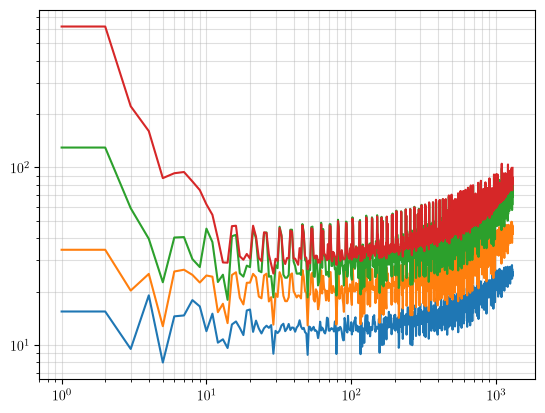

In [11]:
rec0 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)#*(900/1300)
rec05 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.5_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec1 = fits.getdata(os.path.join(calib_dir,'rec','pyr1.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec2 = fits.getdata(os.path.join(calib_dir,'rec','pyr2.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)

plt.figure()
plt.loglog(np.arange(rec0.shape[0])+1,np.diag(rec0 @ rec0.T))
plt.loglog(np.arange(rec05.shape[0])+1,np.diag(rec05 @ rec05.T))
plt.loglog(np.arange(rec1.shape[0])+1,np.diag(rec1 @ rec1.T))
plt.loglog(np.arange(rec2.shape[0])+1,np.diag(rec2 @ rec2.T))
plt.grid(which='both',alpha=0.4)

In [12]:
# wvl = 1300
# rec48x48 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_48x48_wvl{wvl}_bmc2k_vlt_1300modes_rec.fits'),1)
# rec36x36 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_36x36_wvl{wvl}_bmc2k_vlt_800modes_rec.fits'),1)
# rec24x24 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_24x24_wvl{wvl}_bmc2k_vlt_300modes_rec.fits'),1)
# rec14x14 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_14x14_wvl{wvl}_bmc2k_vlt_100modes_rec.fits'),1)
# rec10x10 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_10x10_wvl{wvl}_bmc2k_vlt_54modes_rec.fits'),1)

# def plot_rec_cov(rec,nSubap:int=48):
#     plt.loglog(np.arange(rec.shape[0])+1,np.diag(rec @ rec.T)*(nSubap**2)/(48**2))

# plt.figure()
# plot_rec_cov(rec48x48,nSubap=48)
# plot_rec_cov(rec36x36,nSubap=36)
# plot_rec_cov(rec24x24,nSubap=24)
# plot_rec_cov(rec14x14,nSubap=14)
# plot_rec_cov(rec10x10,nSubap=10)
# plt.grid(which='both',alpha=0.4)